# GRU MODEL

# Imports

In [11]:

# %%
import os
import sys
import importlib
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib import gridspec
import plotly.express as px
import numpy as np

sys.path.append("../src")

import create_datasets
importlib.reload(create_datasets)  # reload to pick latest changes

from create_datasets import (
    denormalize_xy,
    to_latlon,
    _discover_parquet_files,
    _resample_trajectory,
    _convert_latlon_to_xy,
    _apply_normalization,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

# Load datasets

In [24]:
train_data, val_data, test_data = create_datasets.create_datasets(
    input_files="../data/processed",
    ship_type="Cargo",
    with_full_data=False,
    json_dir="../data/normalization"
)

batch_size = 64

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_data,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_data,  batch_size=1,          shuffle=False)

len(train_data), len(val_data), len(test_data)

Discovered 3507 parquet files from 441 vessels.
Total loaded trajectories: 3507
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
Total resampled trajectories: 3514


ValueError: Reference latitude and longitude file not found. Set with_full_data=True to create it.

# Model definition

In [4]:
input_size = 7
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.1

class GRUNet(nn.Module):
    def __init__(self, input_dim=input_size, hidden_dim=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_dim, 2)  # output: X, Y

    def forward(self, x):
        # x: (B, 29, 7)
        out, _ = self.gru(x)        # (B, 29, H)
        last = out[:, -1, :]        # (B, H)
        pred_xy = self.fc(last)     # (B, 2)
        return pred_xy

model = GRUNet().to(device)
model


GRUNet(
  (gru): GRU(7, 128, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)

# Training loop

In [56]:
print("=== TRAINING SETUP ===")

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

num_epochs = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = model.to(device)
print(f"Model moved to: {device}")

print(f"\nTraining configuration:")
print(f"Loss function: MSE Loss")
print(f"Optimizer: Adam (lr=0.001)")
print(f"Scheduler: ReduceLROnPlateau")
print(f"Epochs: {num_epochs}")
print(f"Device: {device}")

=== TRAINING SETUP ===
Model moved to: cuda

Training configuration:
Loss function: MSE Loss
Optimizer: Adam (lr=0.001)
Scheduler: ReduceLROnPlateau
Epochs: 50
Device: cuda


In [57]:
# Save the trained model
def save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath):
    """
    Save model weights, optimizer state, and training history
    """
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'epoch': len(train_losses)
    }, filepath)
    print(f"Model saved to {filepath}")

# Load the saved model
def load_model_and_training_state(filepath):
    """
    Load model weights, optimizer state, and training history
    """
    checkpoint = torch.load(filepath)

    # recreate GRU model exactly like training
    model = GRUNet(
        input_dim=input_size,
        hidden_dim=HIDDEN_SIZE,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    )

    model.load_state_dict(checkpoint['model_state_dict'])

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    return model, optimizer, checkpoint['train_losses'], checkpoint['val_losses'], checkpoint['epoch']


In [58]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs):
    """
    Training loop with validation
    """
    print("=== STARTING TRAINING ===")
    
    train_losses = []
    val_losses = []
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)
            
            # Zero gradients
            optimizer.zero_grad()
            
            # Forward pass  (GRU returns ONLY outputs)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)  # no "_"
                loss = criterion(outputs, targets)
                val_loss += loss.item()
        
        # Average losses
        train_loss /= len(train_loader)
        val_loss /= len(val_loader)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Print progress
        if (epoch + 1) % 5 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f'Epoch [{epoch+1:02d}/{num_epochs}] | '
                  f'Train Loss: {train_loss:.6f} | '
                  f'Val Loss: {val_loss:.6f} | '
                  f'LR: {current_lr:.6f}')
    
    print("Training completed!")

    # Save after training  (CHANGE FILE NAME !!)
    save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath='gru_model.pth')

    print("Parameters saved after training.\n")

    return train_losses, val_losses


In [59]:
train_losses, val_losses = train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs
)

=== STARTING TRAINING ===
Epoch [05/50] | Train Loss: 0.000266 | Val Loss: 0.000100 | LR: 0.001000
Epoch [10/50] | Train Loss: 0.000255 | Val Loss: 0.000116 | LR: 0.001000
Epoch [15/50] | Train Loss: 0.000217 | Val Loss: 0.000091 | LR: 0.000500
Epoch [20/50] | Train Loss: 0.000188 | Val Loss: 0.000097 | LR: 0.000250
Epoch [25/50] | Train Loss: 0.000164 | Val Loss: 0.000116 | LR: 0.000125
Epoch [30/50] | Train Loss: 0.000152 | Val Loss: 0.000118 | LR: 0.000063
Epoch [35/50] | Train Loss: 0.000135 | Val Loss: 0.000122 | LR: 0.000063
Epoch [40/50] | Train Loss: 0.000124 | Val Loss: 0.000128 | LR: 0.000031
Epoch [45/50] | Train Loss: 0.000117 | Val Loss: 0.000128 | LR: 0.000016
Epoch [50/50] | Train Loss: 0.000108 | Val Loss: 0.000134 | LR: 0.000008
Training completed!
Model saved to gru_model.pth
Parameters saved after training.



# Results

### Final Metrics

In [21]:
#recreate gru model architecture
model = GRUNet().to(device)
state_dict = torch.load("gru_model.pth", map_location=device)
model.load_state_dict(state_dict)
model.eval()


criterion = nn.MSELoss()

def evaluate_loss(model, dataloader):
    total_loss = 0.0
    count = 0
    with torch.no_grad():
        for batch in dataloader:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            total_loss += loss.item()
            count += 1

    return total_loss / count


train_loss_final = evaluate_loss(model, train_loader)
val_loss_final = evaluate_loss(model, val_loader)
test_loss_final = evaluate_loss(model, test_loader)

print("Final Metrics:")
print(f"Training Loss: {train_loss_final:.6f}")
print(f"Validation Loss: {val_loss_final:.6f}")
print(f"Test Loss: {test_loss_final:.6f}")

RuntimeError: Error(s) in loading state_dict for GRUNet:
	Missing key(s) in state_dict: "gru.weight_ih_l0", "gru.weight_hh_l0", "gru.bias_ih_l0", "gru.bias_hh_l0", "gru.weight_ih_l1", "gru.weight_hh_l1", "gru.bias_ih_l1", "gru.bias_hh_l1", "fc.weight", "fc.bias". 
	Unexpected key(s) in state_dict: "model_state_dict", "optimizer_state_dict", "train_losses", "val_losses", "epoch". 

### Final Metrics

In [7]:
#recreate gru model architecture
model = GRUNet().to(device)

checkpoint = torch.load("gru_model.pth",map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

criterion = nn.MSELoss()

def evaluate_loss(model, dataloader):
    total_loss = 0.0
    count = 0
    with torch.no_grad():
        for batch in dataloader:
            inputs = batch["input"].to(device)
            targets = batch["target"].to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            total_loss += loss.item()
            count += 1

    return total_loss / count


train_loss_final = evaluate_loss(model, train_loader)
val_loss_final = evaluate_loss(model, val_loader)
test_loss_final = evaluate_loss(model, test_loader)

print("Final Metrics:")
print(f"Training Loss: {train_loss_final:.6f}")
print(f"Validation Loss: {val_loss_final:.6f}")
print(f"Test Loss: {test_loss_final:.6f}")

NameError: name 'train_loader' is not defined

### Plot losses

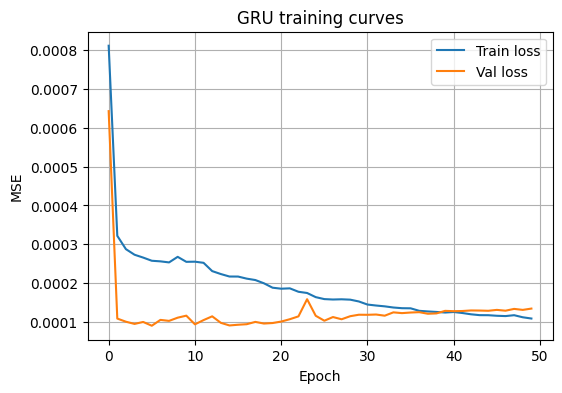

In [61]:
#curves
plt.figure(figsize=(6,4))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.title("GRU training curves")
plt.grid(True)
plt.show()

### Predict a full trajectory

In [26]:
with open("reference_latlon.json", "r") as f:
    ref = json.load(f)
REF_LAT = ref["mean_latitude"]
REF_LON = ref["mean_longitude"]

def build_full_normalized_trajectories(
    input_root="../data/processed",
    ship_type="Cargo",
    max_traj=None  
):
    parquet_files = _discover_parquet_files(input_root, ship_type)
    if max_traj is not None:
        parquet_files = parquet_files[:max_traj]

    trajectories = []

    for file in parquet_files:
        df = pd.read_parquet(file)
        df = df.dropna().reset_index(drop=True)
        df = df[['Timestamp', 'Latitude', 'Longitude', 'SOG', 'COG']]
        df = df.sort_values('Timestamp').reset_index(drop=True)

        resampled = _resample_trajectory(df)
        if resampled is None:
            continue
        if isinstance(resampled, list):
            segments = resampled
        else:
            segments = [resampled]

        for seg in segments:
            # COG -> sin/cos
            cog_rad = np.deg2rad(seg['COG'].values)
            seg['COG_sin'] = np.sin(cog_rad)
            seg['COG_cos'] = np.cos(cog_rad)
            seg = seg.drop(columns=['COG'])

            # Lat/Lon -> X/Y
            seg = _convert_latlon_to_xy(seg, REF_LAT, REF_LON)

            # Delta X/Y
            seg['Delta_X'] = seg['X'].diff()
            seg['Delta_Y'] = seg['Y'].diff()
            seg = seg.iloc[1:] 

            trajectories.append(seg)

    # Normalisation
    trajectories_norm = _apply_normalization(trajectories)
    return trajectories_norm

full_trajs_norm = build_full_normalized_trajectories(
    input_root="../data/processed",
    ship_type="Cargo",
    max_traj=None
)

len(full_trajs_norm)


Discovered 3507 parquet files from 441 vessels.
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps


3514

In [62]:
def predict_full_windowed(df_norm):
    """
    prevision without recursion
    """
    feats = df_norm[["X","Y","Delta_X","Delta_Y","SOG","COG_sin","COG_cos"]].values
    T = feats.shape[0]

    if T <= 30:
        return None, None

    true_xy_norm = feats[:, :2]
    pred_xy_list = []

    for t in range(29, T-1): 
        window = feats[t-29:t]
        x = torch.from_numpy(window).float().unsqueeze(0).to(device)

        with torch.no_grad():
            pred_xy = model(x).cpu().numpy()[0]

        pred_xy_list.append(pred_xy)

    pred_xy_norm = np.vstack([
        true_xy_norm[:29], 
        np.array(pred_xy_list)
    ])

    return true_xy_norm, pred_xy_norm


def visualize_full_trajectory(idx=None):
    if idx is None:
        idx = np.random.randint(len(full_trajs_norm))

    df_norm = full_trajs_norm[idx]
    print(f"Trajectory index {idx}, length {len(df_norm)}")

    true_xy_norm, pred_xy_norm = predict_full_windowed(df_norm)
    if true_xy_norm is None:
        print("Trajectory too short.")
        return

    true_xy_den = denormalize_xy(true_xy_norm)
    pred_xy_den = denormalize_xy(pred_xy_norm)

    true_ll = to_latlon(true_xy_den)
    pred_ll = to_latlon(pred_xy_den)

    lon_true, lat_true = true_ll[:,0], true_ll[:,1]
    lon_pred, lat_pred = pred_ll[:,0], pred_ll[:,1]

    plt.figure(figsize=(7,7))
    plt.plot(lon_true, lat_true, "-o", ms=3, label="True trajectory")
    plt.plot(lon_pred, lat_pred, "-o", ms=3, label="Predicted trajectory")
    plt.scatter(lon_true[-1], lat_true[-1], c="green", s=80, label="True final")
    plt.scatter(lon_pred[-1], lat_pred[-1], c="red",   s=80, label="Pred final")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"Full trajectory {idx} — true vs predicted (windowed)")
    plt.legend()
    plt.grid(True)
    plt.show()


Trajectory index 414, length 886


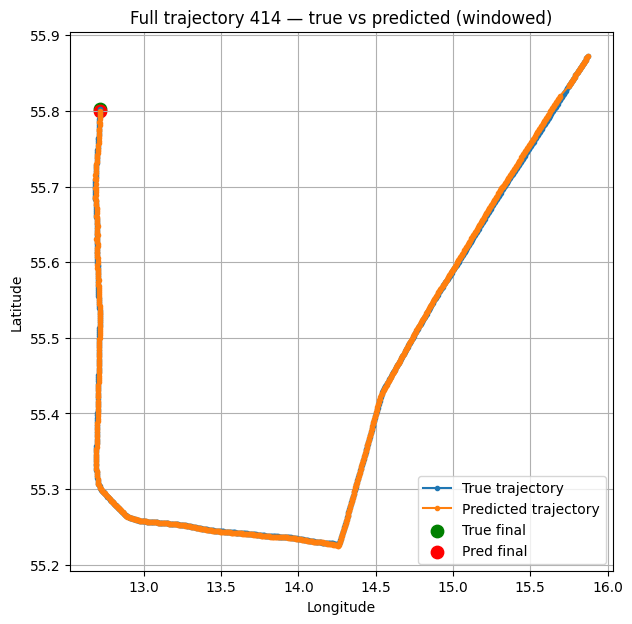

In [63]:
visualize_full_trajectory()


### Anomaly Heatmap 

In [65]:
all_lon = []
all_lat = []
all_err = []

model.eval()
with torch.no_grad():
    for df_norm in full_trajs_norm:

        true_xy_norm, pred_xy_norm = predict_full_windowed(df_norm)
        if true_xy_norm is None:
            continue

        # skip first 29 (warmup)
        true_xy_future = denormalize_xy(true_xy_norm[29:])
        pred_xy_future = denormalize_xy(pred_xy_norm[29:])

        # AJOUT :
        min_len = min(len(true_xy_future), len(pred_xy_future))
        true_xy_future = true_xy_future[:min_len]
        pred_xy_future = pred_xy_future[:min_len]

        # compute vector error (m)
        errors = np.linalg.norm(true_xy_future - pred_xy_future, axis=1)

        # convert to lat/lon
        ll = to_latlon(true_xy_future)
        lon = ll[:,0]
        lat = ll[:,1]

        # extend
        all_lon.extend(lon.tolist())
        all_lat.extend(lat.tolist())
        all_err.extend(errors.tolist())



In [66]:


df_err = pd.DataFrame({
    "lon": all_lon,
    "lat": all_lat,
    "error": all_err
})

df_err = df_err.replace([np.inf, -np.inf], np.nan).dropna()
df_err = df_err[df_err["error"] < 1e6]

print("Heatmap point count:", len(df_err))



Heatmap point count: 2094820


In [70]:
#safe version

df_err_safe = df_err.copy()

MAX_POINTS = 200000  # limite safe pour Plotly

if len(df_err_safe) > MAX_POINTS:
    df_err_safe = df_err_safe.sample(MAX_POINTS, random_state=42)

print("Original data:", len(df_err))
print("Downsampled:", len(df_err_safe))


import plotly.io as pio
pio.renderers.default = "browser"

fig_heatmap = px.density_map(
    df_err_safe,
    lat="lat",
    lon="lon",
    z="error",
    radius=12,
    center=dict(
        lat=df_err_safe["lat"].mean(),
        lon=df_err_safe["lon"].mean()
    ),
    zoom=4,
    color_continuous_scale="Inferno",
)

fig_heatmap.update_layout(
    height=750,
    title="GRU — Spatial Prediction Error Heatmap (Downsampled)"
)

fig_heatmap.show()



Original data: 2094820
Downsampled: 200000


In [69]:
import plotly.io as pio
pio.renderers.default = "browser"

fig_heatmap = px.density_map(
    df_err,
    lat="lat",
    lon="lon",
    z="error",
    radius=14,
    center=dict(
        lat=df_err["lat"].mean(),
        lon=df_err["lon"].mean()
    ),
    zoom=3.8,
    color_continuous_scale="Inferno"
)

fig_heatmap.update_layout(
    title="GRU — Spatial Prediction Error Heatmap",
    height=750,
)
fig_heatmap.show()


### Trajectory error profile

In [77]:
from matplotlib import gridspec

def visualize_trajectory_error(idx=None):

    if idx is None:
        idx = np.random.randint(len(full_trajs_norm))

    df_norm = full_trajs_norm[idx]
    print(f"Trajectory index {idx}, length {len(df_norm)}")

    true_xy_norm, pred_xy_norm = predict_full_windowed(df_norm)
    if true_xy_norm is None:
        print("Trajectory too short.")
        return

    # --- Denormalize full ---
    true_xy = denormalize_xy(true_xy_norm)
    pred_xy = denormalize_xy(pred_xy_norm)

    # --- Convert to lat/lon ---
    true_ll = to_latlon(true_xy)
    pred_ll = to_latlon(pred_xy)

    lon_true, lat_true = true_ll[:,0], true_ll[:,1]
    lon_pred, lat_pred = pred_ll[:,0], pred_ll[:,1]

    # --- ALIGN lengths ---
    min_len = min(len(true_xy), len(pred_xy))

    true_xy = true_xy[:min_len]
    pred_xy = pred_xy[:min_len]

    lon_true = lon_true[:min_len]
    lat_true = lat_true[:min_len]

    lon_pred = lon_pred[:min_len]
    lat_pred = lat_pred[:min_len]

    # --- Compute error ---
    error = np.linalg.norm(true_xy - pred_xy, axis=1)
    error[:29] = 0.0   # warmup

    # --- Plot setup ---
    fig = plt.figure(figsize=(10, 12))
    gs = gridspec.GridSpec(2, 1, height_ratios=[2, 1])

    # ===============================
    # 1) TRAJECTORY MAP
    # ===============================
    ax1 = fig.add_subplot(gs[0])

    ax1.plot(lon_true, lat_true, "-o", ms=3, label="True", color="blue")
    ax1.plot(lon_pred, lat_pred, "-o", ms=3, label="Pred", color="red")

    sc = ax1.scatter(
        lon_true, lat_true,
        c=error,
        cmap="inferno",
        s=15 + 80 * (error / (error.max() + 1e-6)),  # SAME LENGTH AS lon_true
        alpha=0.8
    )

    plt.colorbar(sc, ax=ax1, label="Error (m)")

    ax1.set_title(f"Trajectory {idx} — Error Overlay")
    ax1.set_xlabel("Longitude")
    ax1.set_ylabel("Latitude")
    ax1.legend()
    ax1.grid(True)

    # ===============================
    # 2) ERROR PROFILE
    # ===============================
    ax2 = fig.add_subplot(gs[1])

    ax2.plot(error, color="black", linewidth=2)
    ax2.scatter(np.argmax(error), error.max(), color="red", s=90, label="Max err")

    ax2.set_title("Prediction Error Over Time")
    ax2.set_xlabel("Timestep")
    ax2.set_ylabel("Error (m)")
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.show()


Trajectory index 2196, length 1418


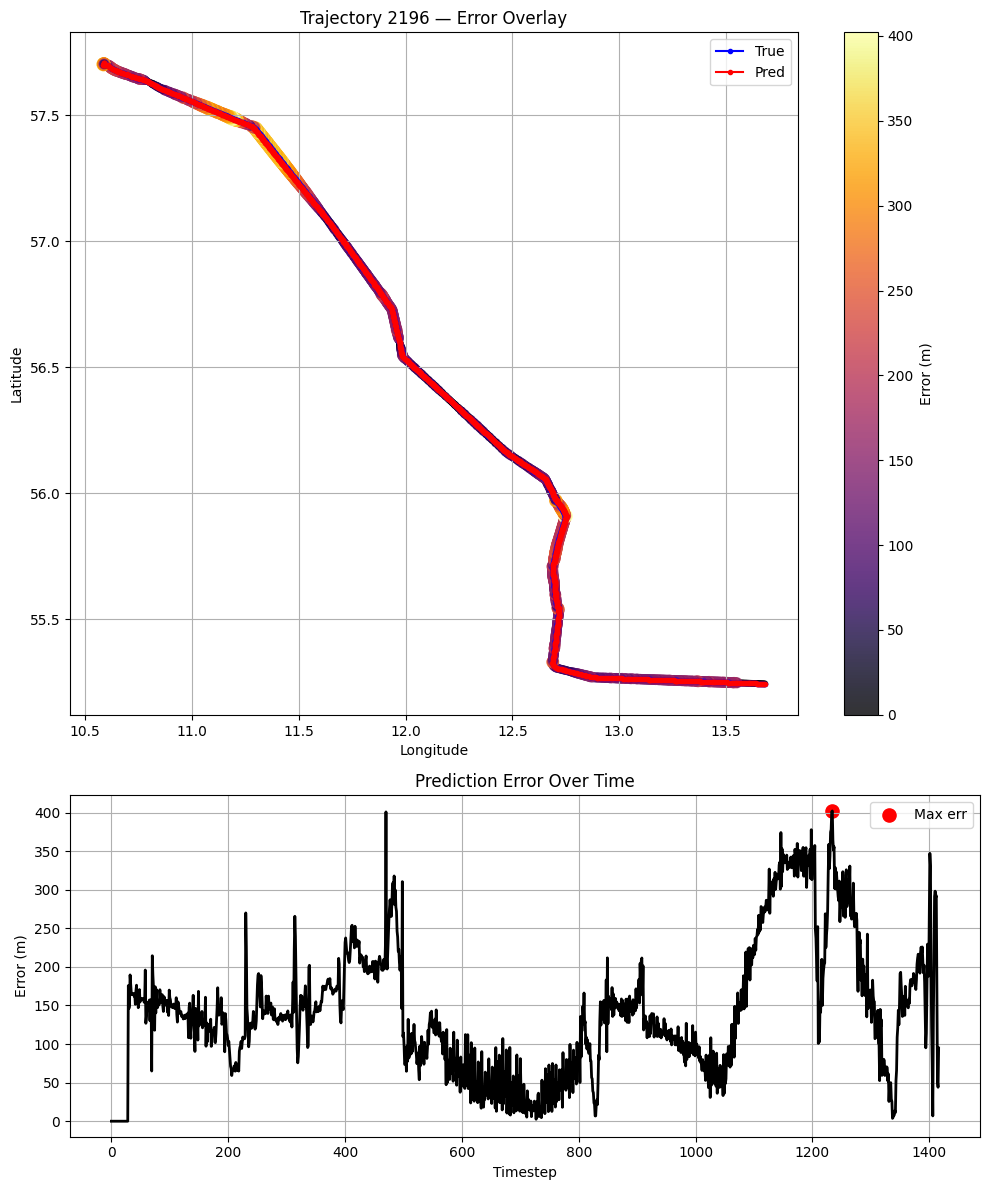

In [78]:
visualize_trajectory_error()


Trajectory index 42, length 506


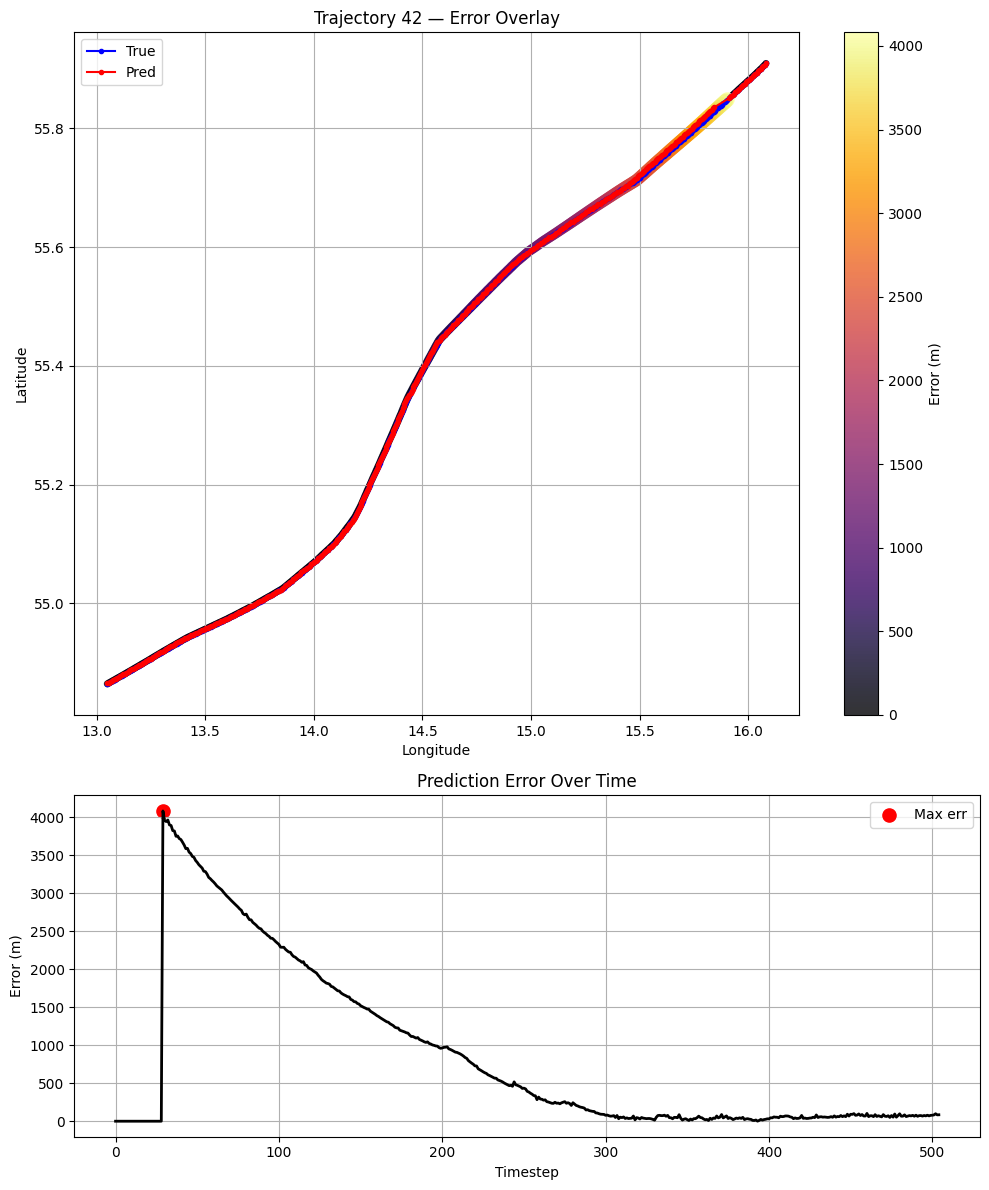

In [79]:
visualize_trajectory_error(idx=42)
